In [23]:
import os

os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"

from pathlib import Path
import csv
from PIL import Image

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Dataset, DataLoader

In [ ]:
class CifarDataset(Dataset):
    def __init__(self, image_dir, csv_file, class_to_idx, transform=None):
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.class_to_idx = class_to_idx

        with open(csv_file, 'r', encoding='utf-8', newline='') as f:
            reader = csv.DictReader(f)
            self.samples = [
                (self.image_dir / f"{row['id']}.png", class_to_idx[row["label"]])
                for row in reader
            ]

        if self.transform is None:
            self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        
        return image,label

In [11]:
class_to_idx = {
    "airplane": 0,
    "automobile": 1,
    "bird": 2,
    "cat": 3,
    "deer":4 ,
    "dog": 5,
    "frog": 6,
    "horse": 7,
    "ship": 8,
    "truck": 9,
}

train_dataset = CifarDataset(image_dir="data/cifar-10/train", 
                             csv_file="data/cifar-10/trainLabels.csv",
                             class_to_idx=class_to_idx)

torch.Size([3, 32, 32])
torch.float32
9
50000


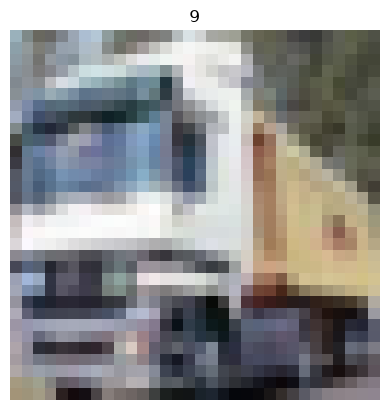

In [12]:
image, label = train_dataset[1]

print(image.shape)
print(image.dtype)
print(label)
print(len(train_dataset))

img = image.permute(1, 2, 0).numpy() 
plt.imshow(img)
plt.axis('off')
plt.title(label)
plt.show()

In [18]:
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=4,
)

In [19]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 5
running_loss = 0
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f'Эпоха [{epoch+1}/{num_epochs}], Потери: {running_loss/len(train_loader):.4f}')

Эпоха [1/5], Потери: 1.6978
Эпоха [2/5], Потери: 3.0426
Эпоха [3/5], Потери: 4.2517
Эпоха [4/5], Потери: 5.3611
Эпоха [5/5], Потери: 6.3947


In [25]:
test_dataset = CIFAR10(
    root="./data/cifar-10-torch",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)

100.0%


In [26]:
model.eval()

correct = 0
total = 0
total_loss = 0.0

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        correct += (predictions == labels).sum().item()
        total += batch_size
        total_loss += loss.item() * batch_size

accuracy = 100 * correct / total
avg_loss = total_loss / total

print(f"Test accuracy: {accuracy:.2f}%")
print(f"Test loss: {avg_loss:.4f}")

Test accuracy: 63.56%
Test loss: 1.0296


In [27]:
torch.save(model.state_dict(), "cifar_cnn.pth")